# PHÂN CỤM KHÁCH HÀNG BẰNG THUẬT TOÁN K-MEANS

## 1. Mục tiêu

Notebook này thực hiện quá trình xây dựng và phân tích mô hình phân cụm khách hàng bằng thuật toán K-Means.

Mục tiêu chính:

- Phân chia khách hàng thành các nhóm có đặc điểm tương đồng.
- Phân tích hành vi khách hàng dựa trên độ tuổi, giới tính, thu nhập và điểm chi tiêu.
- Xác định số lượng cụm phù hợp.
- Đánh giá chất lượng mô hình phân cụm.
- Trực quan hóa kết quả để nhận diện đặc điểm của từng nhóm khách hàng.

## 2. Dữ liệu sử dụng

Sử dụng bộ dữ liệu Mall Customers, bao gồm các thuộc tính:

- CustomerID: Mã khách hàng.
- Gender: Giới tính.
- Age: Độ tuổi.
- Annual Income (k$): Thu nhập hàng năm.
- Spending Score (1-100): Điểm chi tiêu.

## 3. Phương pháp thực hiện

Quá trình phân cụm được thực hiện theo các bước:

1. Chuẩn bị và lựa chọn các thuộc tính đầu vào.
2. Chuẩn hóa dữ liệu.
3. Khởi tạo mô hình K-Means.
4. Huấn luyện mô hình và xác định các cụm.
5. Sử dụng phương pháp Elbow để khảo sát số cụm.
6. Đánh giá chất lượng phân cụm bằng các chỉ số.
7. Trực quan hóa và phân tích kết quả.

## 4. Công cụ và thư viện

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn

In [9]:
# =====================================================
# 1. KẾT NỐI THƯ VIỆN VÀ NẠP DỮ LIỆU
# =====================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
import sys

# Thiết lập đường dẫn thư mục dự án
PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data/raw/Mall_Customers.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Đường dẫn dữ liệu
DATA_PATH = PROJECT_ROOT / "data/raw/Mall_Customers.csv"

# Đọc dữ liệu
df = pd.read_csv(DATA_PATH)

print("ĐÃ NẠP DỮ LIỆU THÀNH CÔNG!")
print("=" * 50)

print("Kích thước dữ liệu:", df.shape)

print("\n5 DÒNG DỮ LIỆU ĐẦU TIÊN:")
display(df.head())

print("\nTHÔNG TIN CÁC THUỘC TÍNH:")
df.info()

ĐÃ NẠP DỮ LIỆU THÀNH CÔNG!
Kích thước dữ liệu: (200, 5)

5 DÒNG DỮ LIỆU ĐẦU TIÊN:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



THÔNG TIN CÁC THUỘC TÍNH:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB


## 2. LỰA CHỌN ĐẶC TRƯNG VÀ CHUẨN HÓA DỮ LIỆU

### 2.1. Lựa chọn đặc trưng

Trong quá trình phân cụm, chúng ta sử dụng 4 thuộc tính:

- Gender: Giới tính khách hàng.
- Age: Độ tuổi.
- Annual Income (k$): Thu nhập hàng năm.
- Spending Score (1-100): Điểm chi tiêu.

Loại bỏ CustomerID vì đây chỉ là mã định danh khách hàng, không phản ánh hành vi tiêu dùng.

### 2.2. Mã hóa giới tính

Chuyển dữ liệu giới tính từ dạng chữ sang dạng số:

- Male = 0
- Female = 1

### 2.3. Chuẩn hóa dữ liệu

Sử dụng MinMaxScaler để đưa các đặc trưng về khoảng giá trị từ 0 đến 1.

Việc chuẩn hóa giúp các thuộc tính có thang đo khác nhau không làm ảnh hưởng quá mức đến khoảng cách Euclidean trong thuật toán K-Means.

In [10]:
# =====================================================
# 2. LỰA CHỌN ĐẶC TRƯNG VÀ CHUẨN HÓA DỮ LIỆU
# =====================================================

from sklearn.preprocessing import MinMaxScaler

# Lựa chọn 4 thuộc tính
feature_columns = [
    "Gender",
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

X_df = df[feature_columns].copy()

# Mã hóa giới tính
X_df["Gender"] = X_df["Gender"].map({
    "Male": 0,
    "Female": 1
})

# Kiểm tra dữ liệu sau mã hóa
assert not X_df.isnull().any().any(), "Dữ liệu có giá trị thiếu!"

# Chuẩn hóa MinMaxScaler
scaler = MinMaxScaler()

X_scaled = scaler.fit_transform(X_df)

# Chuyển về DataFrame để dễ quan sát
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=feature_columns
)

print("CHUẨN BỊ DỮ LIỆU HOÀN TẤT!")
print("=" * 50)

print("Kích thước dữ liệu:", X_scaled.shape)

print("\nDỮ LIỆU SAU CHUẨN HÓA:")
display(X_scaled_df.head())

print("\nGIÁ TRỊ NHỎ NHẤT:")
print(X_scaled_df.min())

print("\nGIÁ TRỊ LỚN NHẤT:")
print(X_scaled_df.max())

CHUẨN BỊ DỮ LIỆU HOÀN TẤT!
Kích thước dữ liệu: (200, 4)

DỮ LIỆU SAU CHUẨN HÓA:


,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,0.0,0.019231,0.000000,0.387755
1,0.0,0.057692,0.000000,0.816327
2,1.0,0.038462,0.008197,0.051020
3,1.0,0.096154,0.008197,0.775510
4,1.0,0.250000,0.016393,0.397959



GIÁ TRỊ NHỎ NHẤT:
Gender                    0.0
Age                       0.0
Annual Income (k$)        0.0
Spending Score (1-100)    0.0
dtype: float64

GIÁ TRỊ LỚN NHẤT:
Gender                    1.0
Age                       1.0
Annual Income (k$)        1.0
Spending Score (1-100)    1.0
dtype: float64


# 3. XÁC ĐỊNH SỐ CỤM K TỐI ƯU

## 3.1. Phương pháp Elbow

Phương pháp Elbow được sử dụng để xác định số lượng cụm phù hợp cho thuật toán K-Means.

Nguyên tắc:
- Thử nghiệm thuật toán với nhiều giá trị K khác nhau.
- Tính toán Inertia tương ứng với từng giá trị K.
- Inertia thể hiện tổng bình phương khoảng cách từ các điểm dữ liệu đến tâm cụm tương ứng.
- Vẽ biểu đồ thể hiện mối quan hệ giữa K và Inertia.

Số cụm K phù hợp thường nằm tại vị trí đường biểu diễn bắt đầu giảm chậm lại, tạo thành hình dạng giống khuỷu tay.

Trong bài toán này, chúng ta thử nghiệm K từ 2 đến 10.

BẮT ĐẦU THỬ NGHIỆM ELBOW
K = 2 | Inertia = 37.272272 | Số vòng lặp = 2
K = 3 | Inertia = 30.110375 | Số vòng lặp = 8
K = 4 | Inertia = 22.390960 | Số vòng lặp = 8
K = 5 | Inertia = 19.081722 | Số vòng lặp = 8
K = 6 | Inertia = 16.876476 | Số vòng lặp = 8
K = 7 | Inertia = 16.056378 | Số vòng lặp = 8
K = 8 | Inertia = 15.736772 | Số vòng lặp = 8
K = 9 | Inertia = 13.672855 | Số vòng lặp = 6
K = 10 | Inertia = 13.047486 | Số vòng lặp = 6

BẢNG KẾT QUẢ THỬ NGHIỆM:


,Số cụm K,Inertia,Số vòng lặp
0,2,37.272272,2
1,3,30.110375,8
2,4,22.390960,8
3,5,19.081722,8
4,6,16.876476,8
5,7,16.056378,8
6,8,15.736772,8
7,9,13.672855,6
8,10,13.047486,6


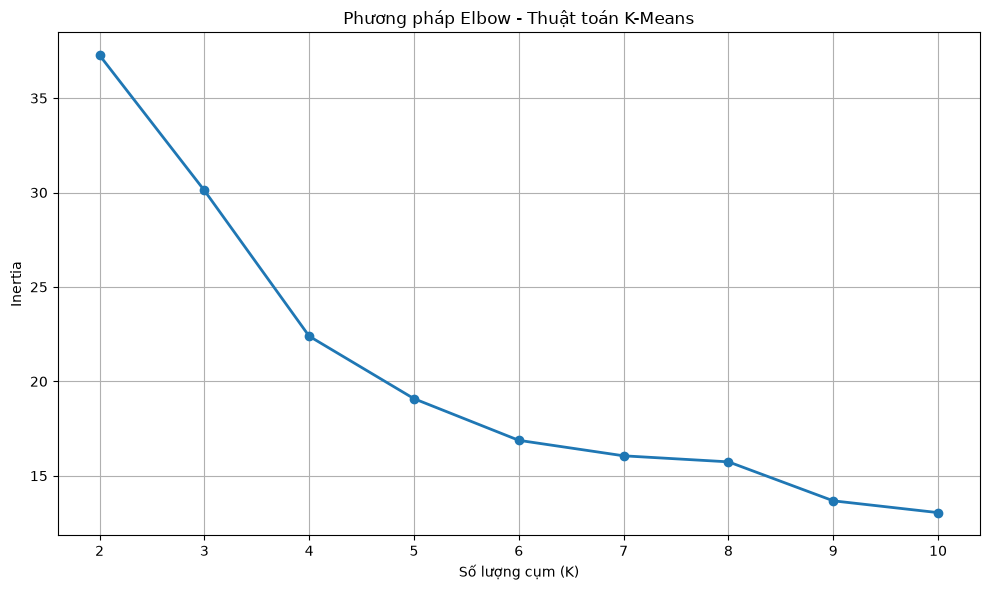


ĐÃ HOÀN THÀNH PHÂN TÍCH ELBOW!


In [11]:
# =====================================================
# 3. XÁC ĐỊNH SỐ CỤM K TỐI ƯU BẰNG ELBOW
# =====================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from src.models.kmeans import KMeans

# Chuyển dữ liệu sang mảng NumPy
X = np.asarray(X_scaled, dtype=float)

# Các giá trị K cần thử nghiệm
k_values = range(2, 11)

inertias = []
iterations = []

print("BẮT ĐẦU THỬ NGHIỆM ELBOW")
print("=" * 55)

for k in k_values:

    model = KMeans(
        n_clusters=k,
        max_iter=300,
        random_state=42
    )

    model.fit(X)

    inertias.append(model.inertia_)
    iterations.append(model.n_iter_)

    print(
        f"K = {k} | "
        f"Inertia = {model.inertia_:.6f} | "
        f"Số vòng lặp = {model.n_iter_}"
    )

# Tạo bảng kết quả
elbow_results = pd.DataFrame({
    "Số cụm K": list(k_values),
    "Inertia": inertias,
    "Số vòng lặp": iterations
})

print("\nBẢNG KẾT QUẢ THỬ NGHIỆM:")
display(elbow_results)

# Vẽ biểu đồ Elbow
plt.figure(figsize=(10, 6))

plt.plot(
    list(k_values),
    inertias,
    marker="o",
    linewidth=2
)

plt.title("Phương pháp Elbow - Thuật toán K-Means")
plt.xlabel("Số lượng cụm (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True)

plt.tight_layout()

# Lưu biểu đồ
output_dir = Path(
    "reports/figures/customer_segmentation/02_training"
)

output_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_dir / "elbow_method_notebook.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nĐÃ HOÀN THÀNH PHÂN TÍCH ELBOW!")

# 3.2. ĐÁNH GIÁ CHẤT LƯỢNG PHÂN CỤM

Sau khi xác định số cụm K sơ bộ bằng phương pháp Elbow, chúng ta tiếp tục đánh giá chất lượng phân cụm thông qua ba chỉ số:

**1. Silhouette Score (Hệ số bóng):**
- Đánh giá mức độ tương đồng của một điểm dữ liệu với cụm của nó so với các cụm khác.
- Giá trị càng cao thì chất lượng phân cụm càng tốt.

**2. Davies-Bouldin Index:**
- Đánh giá mức độ tương đồng giữa các cụm.
- Giá trị càng thấp thì các cụm càng tách biệt và chất lượng phân cụm càng tốt.

**3. Calinski-Harabasz Score:**
- Đánh giá tỷ lệ giữa độ phân tán giữa các cụm và độ phân tán bên trong cụm.
- Giá trị càng cao thì chất lượng phân cụm thường càng tốt.

Chúng ta thử nghiệm các giá trị K từ 2 đến 10 để tìm ra số cụm phù hợp nhất.

BẮT ĐẦU ĐÁNH GIÁ CHẤT LƯỢNG PHÂN CỤM
K = 2 | Silhouette = 0.5195 | DBI = 0.8173 | CH = 262.4746
K = 3 | Silhouette = 0.3966 | DBI = 1.0196 | CH = 185.0609
K = 4 | Silhouette = 0.3642 | DBI = 1.1400 | CH = 187.5897
K = 5 | Silhouette = 0.3706 | DBI = 1.0185 | CH = 172.7039
K = 6 | Silhouette = 0.3771 | DBI = 1.0036 | CH = 160.4858
K = 7 | Silhouette = 0.3549 | DBI = 1.1029 | CH = 141.4873
K = 8 | Silhouette = 0.3435 | DBI = 1.0569 | CH = 123.6538
K = 9 | Silhouette = 0.3134 | DBI = 1.0974 | CH = 127.4848
K = 10 | Silhouette = 0.3178 | DBI = 1.0758 | CH = 119.1414

BẢNG SO SÁNH CHẤT LƯỢNG PHÂN CỤM:


,K,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score,Inertia,Iterations
0,2,0.5195,0.8173,262.4746,37.2723,2
1,3,0.3966,1.0196,185.0609,30.1104,8
2,4,0.3642,1.1400,187.5897,22.3910,8
3,5,0.3706,1.0185,172.7039,19.0817,8
4,6,0.3771,1.0036,160.4858,16.8765,8
5,7,0.3549,1.1029,141.4873,16.0564,8
6,8,0.3435,1.0569,123.6538,15.7368,8
7,9,0.3134,1.0974,127.4848,13.6729,6
8,10,0.3178,1.0758,119.1414,13.0475,6


ĐÃ LƯU BẢNG KẾT QUẢ!


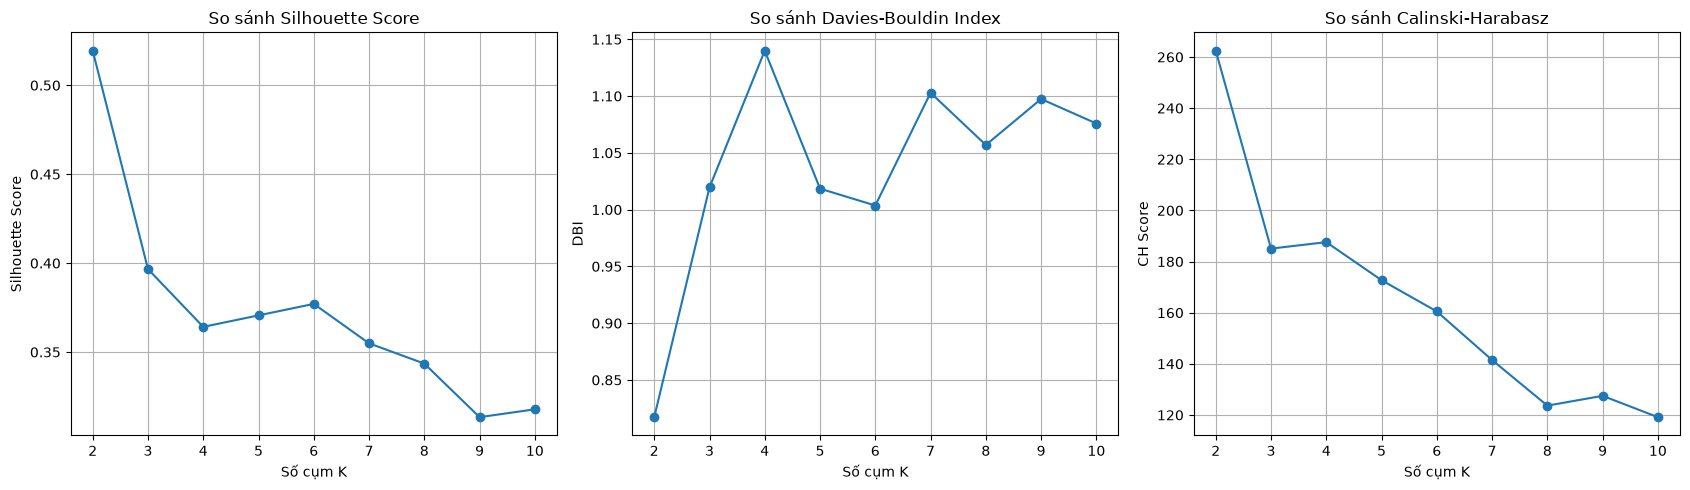


HOÀN THÀNH ĐÁNH GIÁ CHẤT LƯỢNG PHÂN CỤM!


In [12]:
# =====================================================
# 3.3. ĐÁNH GIÁ CHẤT LƯỢNG PHÂN CỤM
# =====================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

from src.models.kmeans import KMeans

# Chuẩn bị dữ liệu
X = np.asarray(X_scaled, dtype=float)

results = []

print("BẮT ĐẦU ĐÁNH GIÁ CHẤT LƯỢNG PHÂN CỤM")
print("=" * 60)

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        max_iter=300,
        random_state=42
    )

    labels = model.fit_predict(X)

    silhouette = silhouette_score(X, labels)

    dbi = davies_bouldin_score(X, labels)

    ch = calinski_harabasz_score(X, labels)

    results.append({
        "K": k,
        "Silhouette Score": silhouette,
        "Davies-Bouldin Index": dbi,
        "Calinski-Harabasz Score": ch,
        "Inertia": model.inertia_,
        "Iterations": model.n_iter_
    })

    print(
        f"K = {k} | "
        f"Silhouette = {silhouette:.4f} | "
        f"DBI = {dbi:.4f} | "
        f"CH = {ch:.4f}"
    )

# Tạo bảng kết quả
metrics_df = pd.DataFrame(results)

print("\nBẢNG SO SÁNH CHẤT LƯỢNG PHÂN CỤM:")
display(metrics_df.round(4))

# Lưu kết quả
result_dir = Path("progress_results")
result_dir.mkdir(parents=True, exist_ok=True)

metrics_df.to_csv(
    result_dir / "notebook_clustering_metrics.csv",
    index=False
)

print("ĐÃ LƯU BẢNG KẾT QUẢ!")

# Trực quan hóa các chỉ số
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

axes[0].plot(
    metrics_df["K"],
    metrics_df["Silhouette Score"],
    marker="o"
)
axes[0].set_title("So sánh Silhouette Score")
axes[0].set_xlabel("Số cụm K")
axes[0].set_ylabel("Silhouette Score")
axes[0].grid(True)

axes[1].plot(
    metrics_df["K"],
    metrics_df["Davies-Bouldin Index"],
    marker="o"
)
axes[1].set_title("So sánh Davies-Bouldin Index")
axes[1].set_xlabel("Số cụm K")
axes[1].set_ylabel("DBI")
axes[1].grid(True)

axes[2].plot(
    metrics_df["K"],
    metrics_df["Calinski-Harabasz Score"],
    marker="o"
)
axes[2].set_title("So sánh Calinski-Harabasz")
axes[2].set_xlabel("Số cụm K")
axes[2].set_ylabel("CH Score")
axes[2].grid(True)

plt.tight_layout()
plt.show()

print("\nHOÀN THÀNH ĐÁNH GIÁ CHẤT LƯỢNG PHÂN CỤM!")

# 4. HUẤN LUYỆN MÔ HÌNH K-MEANS CUỐI CÙNG

Sau khi đánh giá các phương án phân cụm, nghiên cứu lựa chọn K = 2 làm số cụm phù hợp.

Các lý do lựa chọn:

- Silhouette Score đạt giá trị cao nhất tại K = 2.
- Davies-Bouldin Index đạt giá trị thấp nhất tại K = 2.
- Calinski-Harabasz Score đạt giá trị cao nhất tại K = 2.

Tiến hành huấn luyện mô hình K-Means cuối cùng với 2 cụm trên bộ dữ liệu đã chuẩn hóa.

Mục tiêu:
- Xác định nhãn cụm cho từng khách hàng.
- Phân chia khách hàng thành 2 nhóm.
- Lưu kết quả phân cụm để phục vụ phân tích tiếp theo.

In [13]:
# =====================================================
# 4.1. HUẤN LUYỆN MÔ HÌNH K-MEANS CUỐI CÙNG
# =====================================================

import numpy as np
import pandas as pd

from pathlib import Path
from src.models.kmeans import KMeans

# Lựa chọn số cụm cuối cùng
FINAL_K = 2

print("HUẤN LUYỆN MÔ HÌNH K-MEANS CUỐI CÙNG")
print("=" * 55)

# Chuẩn bị dữ liệu đã chuẩn hóa
X_final = np.asarray(X, dtype=float)

# Khởi tạo mô hình
final_model = KMeans(
    n_clusters=FINAL_K,
    max_iter=300,
    random_state=42
)

# Huấn luyện và dự đoán nhãn cụm
final_labels = final_model.fit_predict(X_final)

# Gắn nhãn cụm vào dữ liệu ban đầu
clustered_df = df.copy()
clustered_df["Cluster"] = final_labels

print("\nHUẤN LUYỆN HOÀN TẤT!")
print("Số cụm:", FINAL_K)
print("Số vòng lặp:", final_model.n_iter_)
print("Inertia:", final_model.inertia_)

# Hiển thị kết quả
print("\n10 KHÁCH HÀNG ĐẦU TIÊN:")
display(clustered_df.head(10))

# Thống kê số lượng khách hàng mỗi cụm
print("\nSỐ LƯỢNG KHÁCH HÀNG TRONG TỪNG CỤM:")
display(clustered_df["Cluster"].value_counts().sort_index())

# Lưu kết quả
OUTPUT_DIR = Path("progress_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

clustered_df.to_csv(
    OUTPUT_DIR / "final_customer_clusters.csv",
    index=False
)

print("\nĐÃ LƯU KẾT QUẢ PHÂN CỤM!")
print("File: progress_results/final_customer_clusters.csv")

HUẤN LUYỆN MÔ HÌNH K-MEANS CUỐI CÙNG

HUẤN LUYỆN HOÀN TẤT!
Số cụm: 2
Số vòng lặp: 2
Inertia: 37.27227241211877

10 KHÁCH HÀNG ĐẦU TIÊN:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,0
1,2,Male,21,15,81,0
2,3,Female,20,16,6,1
3,4,Female,23,16,77,1
4,5,Female,31,17,40,1
5,6,Female,22,17,76,1
6,7,Female,35,18,6,1
7,8,Female,23,18,94,1
8,9,Male,64,19,3,0
9,10,Female,30,19,72,1



SỐ LƯỢNG KHÁCH HÀNG TRONG TỪNG CỤM:


Cluster
0     88
1    112
Name: count, dtype: int64


ĐÃ LƯU KẾT QUẢ PHÂN CỤM!
File: progress_results/final_customer_clusters.csv


# 4.3. PHÂN TÍCH ĐẶC ĐIỂM TỪNG CỤM KHÁCH HÀNG

Sau khi hoàn thành quá trình phân cụm bằng thuật toán K-Means, tiến hành phân tích đặc điểm của từng nhóm khách hàng.

Các tiêu chí phân tích:

- Số lượng khách hàng trong mỗi cụm.
- Độ tuổi trung bình.
- Thu nhập trung bình hàng năm.
- Điểm chi tiêu trung bình.
- Tỷ lệ khách hàng nam và nữ.

Mục tiêu là xác định đặc điểm hành vi và khả năng chi tiêu của từng nhóm khách hàng.

ĐẶC ĐIỂM TỪNG CỤM KHÁCH HÀNG


,So_luong,Do_tuoi_TB,Thu_nhap_TB,Diem_chi_tieu_TB,Ty_le_%
Cluster,,,,,
0,88,39.81,62.23,48.51,44.0
1,112,38.10,59.25,51.53,56.0



TỶ LỆ GIỚI TÍNH TRONG TỪNG CỤM (%)


Gender,Female,Male
Cluster,,
0,0.0,100.0
1,100.0,0.0


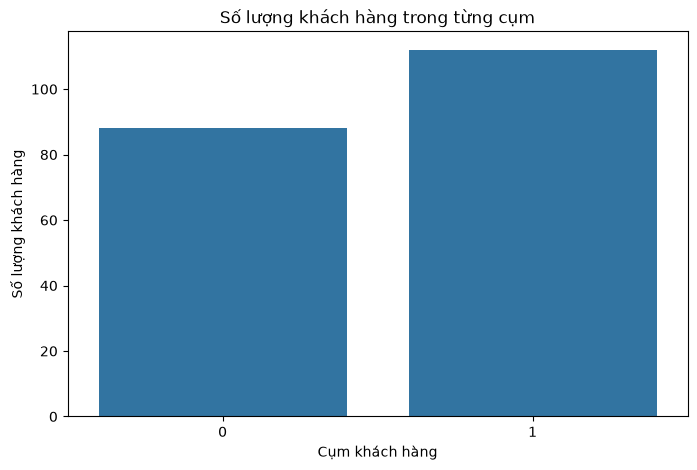


PHÂN TÍCH CỤM KHÁCH HÀNG HOÀN TẤT!


In [14]:
# ==========================================
# PHÂN TÍCH ĐẶC ĐIỂM CÁC CỤM KHÁCH HÀNG
# ==========================================

# 1. Thống kê đặc điểm từng cụm

cluster_profile = clustered_df.groupby("Cluster").agg(
    So_luong=("CustomerID", "count"),
    Do_tuoi_TB=("Age", "mean"),
    Thu_nhap_TB=("Annual Income (k$)", "mean"),
    Diem_chi_tieu_TB=("Spending Score (1-100)", "mean")
).round(2)

# Tính tỷ lệ khách hàng
cluster_profile["Ty_le_%"] = (
    cluster_profile["So_luong"] / len(clustered_df) * 100
).round(2)

print("ĐẶC ĐIỂM TỪNG CỤM KHÁCH HÀNG")
display(cluster_profile)


# 2. Phân tích phân bố giới tính

gender_profile = pd.crosstab(
    clustered_df["Cluster"],
    clustered_df["Gender"],
    normalize="index"
) * 100

gender_profile = gender_profile.round(2)

print("\nTỶ LỆ GIỚI TÍNH TRONG TỪNG CỤM (%)")
display(gender_profile)


# 3. Trực quan hóa số lượng khách hàng

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
    data=clustered_df,
    x="Cluster"
)

plt.title("Số lượng khách hàng trong từng cụm")
plt.xlabel("Cụm khách hàng")
plt.ylabel("Số lượng khách hàng")

plt.show()


print("\nPHÂN TÍCH CỤM KHÁCH HÀNG HOÀN TẤT!")